# ITM 454 - Natural Language Processing
## Final Project: Sentiment Analysis of Khmer Customer Reviews — **04. Transformer: Fine-tuned XLM-R**

---

The BiLSTM (notebook 03) had two problems: **little training data** and **many unknown words** in real Khmer reviews.

**XLM-R** (`xlm-roberta-base`, Conneau et al., 2020) solves both:
- it is a big Transformer that was **already pretrained on 100 languages, including Khmer** (2.5 TB of web text),
  so it already "knows" a lot of Khmer before it sees our reviews;
- it cuts text into **subword pieces**, so (almost) no word is unknown.

We only **fine-tune** it on our reviews, with the same **4 steps** as in class:

1. **Data** → `DataLoader`
2. **NN Model** → `AutoModelForSequenceClassification` (XLM-R + a small classification head)
3. **Loss & Optimizer** → `CrossEntropyLoss` (with class weights) + `AdamW` + learning-rate schedule
4. **Training loop** → predict → loss → `zero_grad` → `backward` → `step`, for 4 epochs

> **⚡ GPU needed.** XLM-R has about 278 million weights. Training takes a few minutes on a GPU, but hours on a normal CPU.
> This notebook needs an **NVIDIA GPU**: on a CPU, training is possible but very slow.

### 0. Setup

**How to run:** open this notebook from the `notebooks/` folder of the project and run all cells (Kernel → Restart & Run All).
The setup cell below goes to the project folder and installs the packages from `requirements.txt`
(see the README for creating the Python environment). All paths in this notebook are relative to the project folder.

**Before this notebook:** Run **notebook 01** first (its outputs are already in the repository). This notebook needs an **NVIDIA GPU** (about 2 minutes on an RTX 4060 laptop GPU).

| Input file | Created by |
|---|---|
| `data/processed/*.csv`, `data/processed/settings.json` | notebook 01 |
| `xlm-roberta-base` (about 1.1 GB) | downloaded automatically from Hugging Face on the first run |


| Output | Used by |
|---|---|
| `models/xlmr_best/` (about 1.1 GB, not in the repository) | the web app (Accurate model) |
| `results/metrics/xlmr.json`, `results/predictions/xlmr_*.csv` | notebook 05 |
| `results/figures/04_*.png` | report |

In [ ]:
import os

# 1. Go to the project folder (this notebook is in its notebooks/ folder)
PROJECT_DIR = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
os.chdir(PROJECT_DIR)

# 2. Install the packages (the exact versions we used are in requirements.txt)
%pip install -q -r requirements.txt

# 3. Folders for the outputs
for folder in ["data/processed", "results/predictions", "results/metrics", "results/figures", "models", "src"]:
    os.makedirs(folder, exist_ok=True)
print("Project folder:", os.path.basename(os.path.abspath(".")))

### 1. Import Required Libraries

In [2]:
import os
import re
import sys
import json
import time
import random
import unicodedata

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score, accuracy_score

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from datasets import Dataset, disable_progress_bars
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          get_linear_schedule_with_warmup, set_seed)
disable_progress_bars()

# Seed values for reproducibility
SEED = 45
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
set_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device, f"({torch.cuda.get_device_name(0)})" if device == "cuda" else "")
if device == "cpu":
    print("⚠ No GPU found: training will be very slow (an NVIDIA GPU is recommended).")

Device: cuda (NVIDIA GeForce RTX 4060 Laptop GPU)


#### Khmer font for plots

The default matplotlib font has no Khmer letters, so Khmer text would appear as empty boxes □□□.
We use a Khmer font if one is installed (Noto Sans Khmer, Khmer OS or Khmer UI).

In [4]:
from matplotlib import font_manager

installed_fonts = {font.name for font in font_manager.fontManager.ttflist}
khmer_font = next((name for name in ["Noto Sans Khmer", "Khmer OS", "Khmer UI", "DaunPenh"] if name in installed_fonts), None)
if khmer_font:
    plt.rcParams["font.family"] = [khmer_font, "DejaVu Sans"]   # Khmer font first, normal font as backup
print("Khmer font for plots:", khmer_font or "none found (Khmer text may appear as boxes)")

Khmer font for plots: Khmer OS


### 2. Dataset

The same splits as notebooks 02 and 03.

In [5]:
with open("data/processed/settings.json") as f:
    settings = json.load(f)
label_names = settings["label_names"]                      # ["negative", "positive"]
label2id = {name: i for i, name in enumerate(label_names)}
id2label = {i: name for i, name in enumerate(label_names)}

train = pd.read_csv("data/processed/train.csv")
val = pd.read_csv("data/processed/val.csv")
test_translated = pd.read_csv("data/processed/test_translated.csv")
test_native = pd.read_csv("data/processed/test_native.csv")

for name, data in [("train", train), ("val", val), ("test_translated", test_translated), ("test_native", test_native)]:
    print(f"{name:16s}: {len(data):5d} reviews")

LABEL_SOURCE = settings["test_native_label_source"]
if LABEL_SOURCE == "silver":
    print("\n⚠ test_native uses SILVER (AI) labels → its results are PROVISIONAL.")

train           :  2858 reviews
val             :   357 reviews
test_translated :   358 reviews
test_native     :   214 reviews


### 3. Tokenization (XLM-R SentencePiece)

XLM-R has its **own tokenizer** (SentencePiece, 250,000 subword pieces for 100 languages). It cuts the text into pieces
by itself, so we do **not** need the khmer-nltk segmentation and we keep punctuation, numbers and capital letters
(the model learned them during pretraining).

We only **normalize** the text (`text_km`): Unicode NFC and removal of zero-width characters, like steps 1–2 of `preprocess_text`.

| | BiLSTM (notebook 03) | XLM-R |
|---|---|---|
| Unit | khmer-nltk **words** | **subword pieces** (`▁` = start of a new word) |
| Unknown word | → `<unk>` (meaning lost) | cut into smaller known pieces |

In [6]:
ZERO_WIDTH = re.compile("[\u200b\u200c\u200d\ufeff]")

def normalize_text(text):
    text = unicodedata.normalize("NFC", str(text))   # same letters stored the same way
    return ZERO_WIDTH.sub("", text)                  # remove zero-width characters

for data in [train, val, test_translated, test_native]:
    data["text_norm"] = data["text_km"].apply(normalize_text)

MODEL_NAME = "xlm-roberta-base"
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

example = test_native["text_norm"].iloc[0]
print("Review    :", example)
print("Pieces    :", tokenizer.tokenize(example))
print("Input IDs :", tokenizer(example)["input_ids"])

Review    : Driverឈប់តាមផ្លូវច្រើន មិនប្រាប់ថាឈប់បាយត្រង់ណា ឡានចាស់
Pieces    : ['▁Driver', 'ឈប់', 'តាម', 'ផ្លូវ', 'ច្រើន', '▁មិន', 'ប្រាប់', 'ថា', 'ឈប់', 'បាយ', 'ត្រង់', 'ណា', '▁', 'ឡាន', 'ចាស់']
Input IDs : [0, 131470, 194962, 43481, 81142, 88910, 10995, 209471, 11421, 194962, 162483, 150473, 25991, 6, 188106, 138460, 2]


#### Unknown pieces

How many pieces does the tokenizer not know (`<unk>`)? Compare with the 20.8% unknown words of the BiLSTM on test_native.

In [7]:
# Unknown pieces: compare with the 20.8% unknown words of the BiLSTM on test_native
for name, data in [("test_translated", test_translated), ("test_native", test_native)]:
    ids = [i for text in data["text_norm"] for i in tokenizer(text)["input_ids"]]
    print(f"{name:16s}: {sum(i == tokenizer.unk_token_id for i in ids) / len(ids):.2%} unknown pieces (<unk>)")

test_translated : 0.00% unknown pieces (<unk>)
test_native     : 0.02% unknown pieces (<unk>)


#### How many pieces per review? → `max_length`

The model needs a fixed length. We choose `max_length` so that about **95% of the reviews fit**; longer ones are cut.

count    2858.0
mean       39.7
std        21.7
min         3.0
50%        37.5
95%        75.0
max       100.0


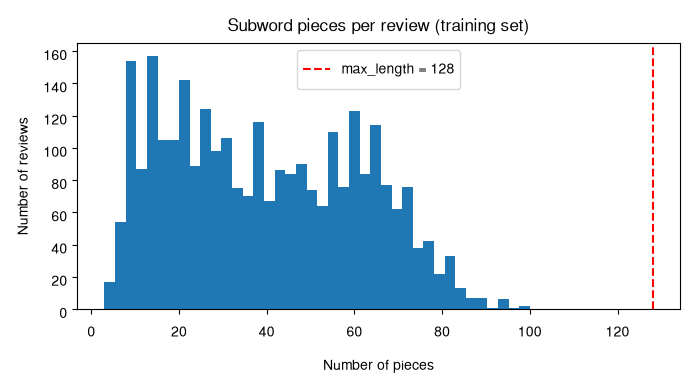

In [8]:
lengths = train["text_norm"].apply(lambda text: len(tokenizer(text)["input_ids"]))   # includes <s> and </s>
print(lengths.describe(percentiles=[0.5, 0.95]).round(1).to_string())

plt.figure(figsize=(7, 4))
plt.hist(lengths, bins=40)
plt.axvline(128, color="red", linestyle="--", label="max_length = 128")
plt.title("Subword pieces per review (training set)")
plt.xlabel("Number of pieces")
plt.ylabel("Number of reviews")
plt.legend()
plt.tight_layout()
plt.savefig("results/figures/04_token_lengths.png", dpi=150)
plt.show()

We use `max_length = 128` pieces. How many reviews fit completely?

In [9]:
max_length = 128
for name, data in [("train", train), ("val", val), ("test_translated", test_translated), ("test_native", test_native)]:
    n = data["text_norm"].apply(lambda text: len(tokenizer(text)["input_ids"]))
    print(f"{name:16s}: {(n <= max_length).mean():.1%} of reviews fit | {(n > max_length).sum()} reviews are cut")

train           : 100.0% of reviews fit | 0 reviews are cut
val             : 100.0% of reviews fit | 0 reviews are cut
test_translated : 100.0% of reviews fit | 0 reviews are cut
test_native     : 100.0% of reviews fit | 0 reviews are cut


### 4. Create the Training Data (DataLoader)

`.map()` runs the tokenizer on every review and adds two columns:
- `input_ids`: the piece IDs, **padded** with `<pad>` to `max_length` (or cut)
- `attention_mask`: 1 = real piece, 0 = padding (the model ignores the padding)

`batch_size=16` (smaller than before: XLM-R needs much more GPU memory).

In [10]:
def tokenize(example):
    return tokenizer(example["text_norm"], padding="max_length", truncation=True, max_length=max_length)

def to_dataset(data):
    dataset = Dataset.from_pandas(data[["text_norm", "label_id"]].rename(columns={"label_id": "label"}), preserve_index=False)
    dataset = dataset.map(tokenize, batched=True)
    return dataset.with_format("torch", columns=["input_ids", "attention_mask", "label"])

train_data, val_data = to_dataset(train), to_dataset(val)
test_translated_data, test_native_data = to_dataset(test_translated), to_dataset(test_native)

batch_size = 16
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(val_data, batch_size=batch_size)
test_translated_loader = DataLoader(test_translated_data, batch_size=batch_size)
test_native_loader = DataLoader(test_native_data, batch_size=batch_size)

batch = next(iter(train_loader))
print(f"Number of training batches: {len(train_loader)}")
print(f"input_ids shape     : {batch['input_ids'].shape}  ({batch_size} reviews x {max_length} pieces)")
print(f"attention_mask shape: {batch['attention_mask'].shape}")
print(f"label shape         : {batch['label'].shape}")
print("\nFirst review of the batch (decoded):", tokenizer.decode(batch["input_ids"][0], skip_special_tokens=True))
print("Real pieces:", batch["attention_mask"][0].sum().item(), "| label:", label_names[batch["label"][0].item()])

Number of training batches: 179
input_ids shape     : torch.Size([16, 128])  (16 reviews x 128 pieces)
attention_mask shape: torch.Size([16, 128])
label shape         : torch.Size([16])

First review of the batch (decoded): គ្មានកន្លែងដាក់ជើងសោះ ម៉ាស៊ីនត្រជាក់គ្មានប្រយោជន៍ អ្នកបើកបរមិនខ្វល់ ហើយមិនអើពើយើងទាំងស្រុង។ នឹងមិនប្រើក្រុមហ៊ុនឡានក្រុងរបស់អ្នកម្តងទៀតឡើយ។
Real pieces: 41 | label: negative


### 5. The Model (XLM-R + classification head)

```
subword IDs (128 per review)                             ← input layer
   ↓  XLM-R encoder: 12 Transformer layers               pretrained on 100 languages incl. Khmer
   ↓  (every piece looks at all other pieces = self-attention)      (batch, 128, 768)
   ↓  vector of the first token <s>                       one review → 768 numbers
   ↓  classification head (dense + tanh + output)        768 → 2 scores (negative, positive)
```

**Fine-tuning vs. training from scratch**
- *From scratch*: all weights start random and must be learned from our 2,858 reviews (like the BiLSTM layers).
- *Fine-tuning*: the 12 layers start from weights that already understand Khmer. Only the small classification head is new;
  everything is then **adjusted slightly** for our task.

| | Professor's Transformer (notebook 19) | **XLM-R (this notebook)** |
|---|---|---|
| Layers | 2 | **12** |
| Trained on | AG News only, **from scratch** | **pretrained** on 2.5 TB of text in 100 languages, then fine-tuned |
| Word vectors | frozen GloVe (English) | its own subword embeddings (fine-tuned) |
| Trainable weights | 195,436 | about **278 million** |

In [11]:
torch.manual_seed(SEED)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(label_names), id2label=id2label, label2id=label2id).to(device)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


The message above is expected: the **classification head** (`classifier.*`) is new and starts random, and the parts used only
for pretraining (`lm_head.*`) are not needed.

In [12]:
def count_parameters(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    frozen = sum(p.numel() for p in model.parameters() if not p.requires_grad)
    print(f"Trainable weights: {trainable:,}")
    print(f"Frozen weights   : {frozen:,}")
    return trainable

n_parameters = count_parameters(model)

def count(module):
    return sum(p.numel() for p in module.parameters() if p.requires_grad)

print(f"\nEmbeddings (250,002 pieces x 768): {count(model.roberta.embeddings):,}")
print(f"12 Transformer layers            : {count(model.roberta.encoder):,}")
print(f"Classification head              : {count(model.classifier):,}")

Trainable weights: 278,045,186
Frozen weights   : 0

Embeddings (250,002 pieces x 768): 192,398,592
12 Transformer layers            : 85,054,464
Classification head              : 592,130


### 6. Loss Function and Optimizer

- **Loss** `CrossEntropyLoss` with **class weights** (from the training set only) on the model's 2 scores (`logits`).
- **Optimizer** `AdamW` (Adam + weight decay 0.01, which keeps the weights small).
- **Learning rate `2e-5`** = 0.00002, which is **50 times smaller** than for the BiLSTM (0.001). The pretrained weights are
  already good: big steps would destroy what XLM-R learned during pretraining ("catastrophic forgetting"). We only want to
  adjust them **gently**.
- **Linear schedule with 10% warmup**: the learning rate starts at 0, grows during the first 10% of the steps (the new
  classification head is still random, so the first updates should be careful), then goes down to 0 at the end.

In [13]:
class_counts = np.bincount(train["label_id"], minlength=len(label_names))
class_weights = torch.tensor(len(train) / (len(label_names) * class_counts), dtype=torch.float32).to(device)
print("Class weights:", dict(zip(label_names, class_weights.cpu().numpy().round(3))))
loss_fn = nn.CrossEntropyLoss(weight=class_weights)

epochs = 4
optimizer = torch.optim.AdamW(model.parameters(), lr=2e-5, weight_decay=0.01)
total_steps = epochs * len(train_loader)
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=int(0.1 * total_steps),
                                            num_training_steps=total_steps)
print(f"Training steps: {total_steps} | warmup steps: {int(0.1 * total_steps)}")

Class weights: {'negative': np.float32(1.0), 'positive': np.float32(1.0)}
Training steps: 716 | warmup steps: 71


#### Learning-rate schedule

The learning rate grows during the first 10% of the steps (warm-up) and then goes down linearly to 0.

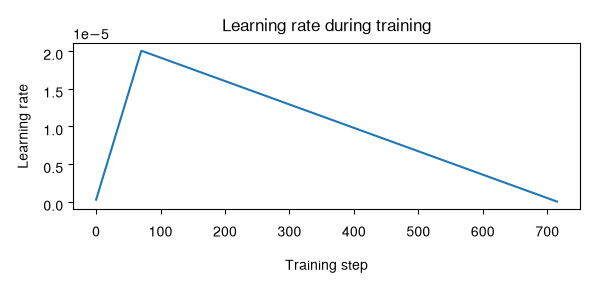

In [14]:
# What the schedule looks like (computed without training)
lrs = [2e-5 * min((step + 1) / int(0.1 * total_steps), (total_steps - step) / (total_steps - int(0.1 * total_steps)))
       for step in range(total_steps)]
plt.figure(figsize=(6, 3))
plt.plot(lrs)
plt.title("Learning rate during training")
plt.xlabel("Training step")
plt.ylabel("Learning rate")
plt.tight_layout()
plt.show()

#### Before training

The classification head is random, so the model is guessing. `evaluate()` returns loss, accuracy and macro-F1.

**Mixed precision** (`torch.autocast`): on a GPU, most calculations use 16-bit numbers instead of 32-bit → about
2× faster and less memory, with almost the same results.

In [15]:
USE_AMP = device == "cuda"
scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)   # keeps small 16-bit gradients from becoming 0

def evaluate(model, loader):
    """Average loss, accuracy and macro-F1 of the model on a dataset (no training)."""
    model.eval()
    total_loss, predictions, labels = 0, [], []
    with torch.no_grad():
        for batch in loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            label = batch["label"].to(device)
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                scores = model(input_ids=input_ids, attention_mask=attention_mask).logits
            total_loss += loss_fn(scores.float(), label).item() * len(label)
            predictions.extend(scores.argmax(dim=1).tolist())
            labels.extend(label.tolist())
    return total_loss / len(loader.dataset), accuracy_score(labels, predictions), f1_score(labels, predictions, average="macro")

val_loss, val_acc, val_f1 = evaluate(model, val_loader)
print(f"Before training → validation accuracy: {val_acc:.3f} | macro-F1: {val_f1:.3f}")

Before training → validation accuracy: 0.501 | macro-F1: 0.334


### 7. Model Training

The **same training loop** as in notebook 03 (no Hugging Face `Trainer`), with three small changes:
- the model gets `input_ids` **and** `attention_mask`, and returns `.logits` (the 2 scores)
- `scheduler.step()` after every batch (learning-rate schedule)
- mixed precision (`autocast` + `scaler`)

We again keep the weights of the epoch with the **best validation macro-F1** (copied to the CPU memory).

In [16]:
def train_model(model, optimizer, epochs):
    history = {"train_loss": [], "val_loss": [], "val_acc": [], "val_macro_f1": []}
    best_f1, best_weights, best_epoch = -1, None, 0

    for epoch in range(epochs):
        model.train()   # training mode
        total_loss = 0

        for batch in train_loader:
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            label = batch["label"].to(device)

            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                scores = model(input_ids=input_ids, attention_mask=attention_mask).logits   # 1. predict
            loss = loss_fn(scores.float(), label)                                          # 2. loss

            optimizer.zero_grad()                       # 3. clear old gradients
            scaler.scale(loss).backward()               # 4. compute gradients
            scaler.step(optimizer)                      # 5. update the weights
            scaler.update()
            scheduler.step()                            # NEW: next learning rate

            total_loss += loss.item() * len(label)

        val_loss, val_acc, val_f1 = evaluate(model, val_loader)
        history["train_loss"].append(total_loss / len(train_loader.dataset))
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["val_macro_f1"].append(val_f1)

        if val_f1 > best_f1:                            # remember the best epoch (copy on the CPU)
            best_f1, best_epoch = val_f1, epoch + 1
            best_weights = {name: value.detach().cpu().clone() for name, value in model.state_dict().items()}

        print(f"Epoch {epoch + 1} | train loss {history['train_loss'][-1]:.4f} | val loss {val_loss:.4f} | "
              f"val acc {val_acc:.3f} | val macro-F1 {val_f1:.3f}")

    model.load_state_dict(best_weights)                 # put the best weights back
    print(f"\nBest epoch: {best_epoch} (validation macro-F1 {best_f1:.3f}) → these weights are restored")
    return history, best_f1, best_epoch

#### Fine-tune the model

4 epochs; we keep the model from the epoch with the best validation macro-F1.

In [17]:
print("Fine-tuning XLM-R...")
start = time.time()
history, best_val_f1, best_epoch = train_model(model, optimizer, epochs)
training_time = time.time() - start
print(f"Training completed in {training_time / 60:.1f} minutes!")
if device == "cuda":
    print(f"Peak GPU memory: {torch.cuda.max_memory_allocated() / 1e9:.1f} GB")

Fine-tuning XLM-R...


Epoch 1 | train loss 0.4727 | val loss 0.2342 | val acc 0.922 | val macro-F1 0.922


Epoch 2 | train loss 0.1629 | val loss 0.2112 | val acc 0.941 | val macro-F1 0.941


Epoch 3 | train loss 0.0991 | val loss 0.1915 | val acc 0.941 | val macro-F1 0.941


Epoch 4 | train loss 0.0651 | val loss 0.1775 | val acc 0.950 | val macro-F1 0.950

Best epoch: 4 (validation macro-F1 0.950) → these weights are restored
Training completed in 2.0 minutes!
Peak GPU memory: 5.6 GB


#### Training curves

Loss (train and validation) and validation macro-F1 after every epoch.

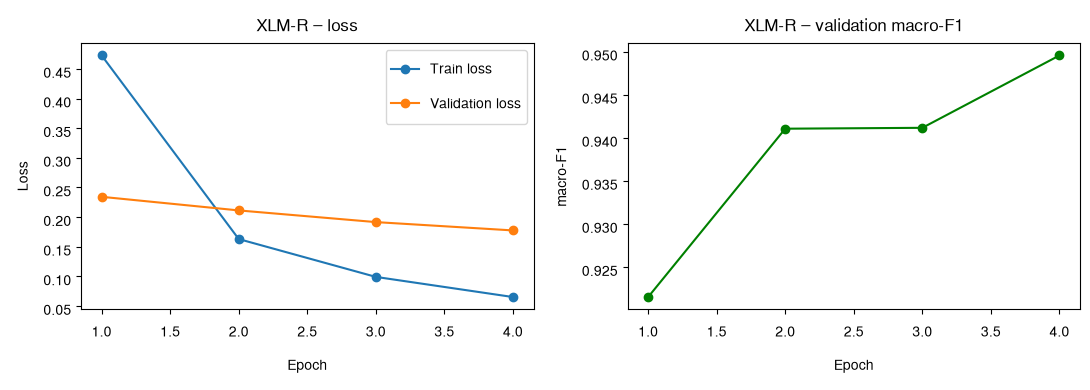

In [18]:
def plot_history(history, title, filename):
    epoch_numbers = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
    ax1.plot(epoch_numbers, history["train_loss"], marker='o', label='Train loss')
    ax1.plot(epoch_numbers, history["val_loss"], marker='o', label='Validation loss')
    ax1.set_title(title + " – loss")
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax2.plot(epoch_numbers, history["val_macro_f1"], marker='o', color="green")
    ax2.set_title(title + " – validation macro-F1")
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('macro-F1')
    plt.tight_layout()
    plt.savefig(filename, dpi=150)
    plt.show()

plot_history(history, "XLM-R", "results/figures/04_training_history.png")

- Unlike the BiLSTM, the **validation loss goes down every epoch** (0.234 → 0.178) and the validation macro-F1 goes up
  (0.922 → 0.941 → 0.941 → **0.950**): no overfitting within 4 epochs. The best epoch is the last one (4).
- Already after **1 epoch** XLM-R (0.922) is better than the best BiLSTM epoch (0.910): the pretraining does most of the work.
- Training took **about 2 minutes** on our laptop GPU (RTX 4060, 5.6 GB of GPU memory). The time depends on the GPU.

### 8. Model Evaluation (Test Sets)

With the best weights restored, we use the two test sets **once**.

=== test_translated (358 reviews) ===
              precision    recall  f1-score   support

    negative      0.989     0.961     0.975       179
    positive      0.962     0.989     0.975       179

    accuracy                          0.975       358
   macro avg      0.975     0.975     0.975       358
weighted avg      0.975     0.975     0.975       358



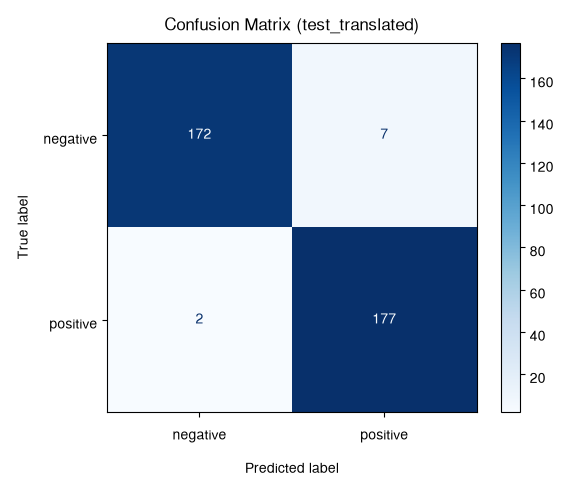

In [19]:
def get_predictions(model, loader):
    model.eval()
    predictions, labels, probabilities = [], [], []
    with torch.no_grad():
        for batch in loader:
            with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=USE_AMP):
                scores = model(input_ids=batch["input_ids"].to(device),
                               attention_mask=batch["attention_mask"].to(device)).logits
            probs = torch.softmax(scores.float(), dim=1)    # 2 scores → 2 probabilities
            predictions.extend(probs.argmax(dim=1).tolist())
            probabilities.extend(probs.tolist())
            labels.extend(batch["label"].tolist())
    return np.array(predictions), np.array(labels), np.array(probabilities)

def evaluate_test_set(loader, name):
    y_pred, y_true, probs = get_predictions(model, loader)
    print(f"=== {name} ({len(y_true)} reviews) ===")
    print(classification_report(y_true, y_pred, target_names=label_names, digits=3))
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=label_names, cmap='Blues')
    plt.title(f"Confusion Matrix ({name})")
    plt.savefig(f"results/figures/04_confusion_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    return y_pred, probs

y_pred_translated, probs_translated = evaluate_test_set(test_translated_loader, "test_translated")

#### test_native: reviews written in Khmer (gold labels)

=== test_native (214 reviews) ===
              precision    recall  f1-score   support

    negative      0.982     0.976     0.979       170
    positive      0.911     0.932     0.921        44

    accuracy                          0.967       214
   macro avg      0.947     0.954     0.950       214
weighted avg      0.968     0.967     0.967       214



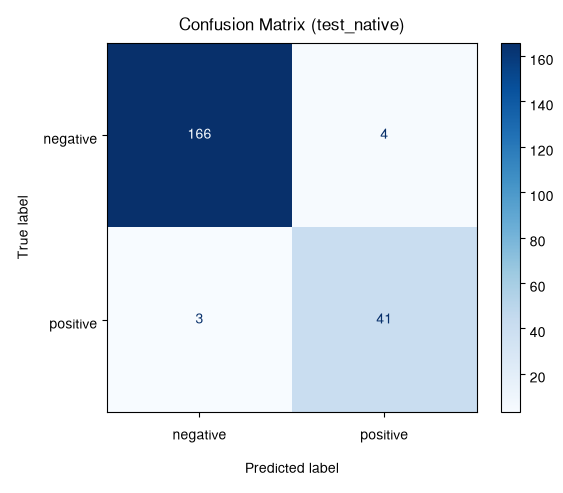

In [20]:
if LABEL_SOURCE == "silver":
    print("⚠ PROVISIONAL: test_native uses silver (AI) labels.\n")
y_pred_native, probs_native = evaluate_test_set(test_native_loader, "test_native")

#### Pure Khmer vs. code-switched (inside test_native)

In [21]:
def macro_f1_by_group(data, y_pred):
    scores = {}
    for group in ["pure_khmer", "code_switched"]:
        mask = (data["language_group"] == group).values
        scores[group] = f1_score(data["label_id"].values[mask], y_pred[mask], average="macro",
                                 labels=[0, 1], zero_division=0)
        print(f"{group:14s}: {mask.sum():3d} reviews | macro-F1 = {scores[group]:.3f}")
    return scores

group_scores = macro_f1_by_group(test_native, y_pred_native)

pure_khmer    : 193 reviews | macro-F1 = 0.962
code_switched :  21 reviews | macro-F1 = 0.724


- **test_translated: macro-F1 0.975** (accuracy 97.5%), the best of the three models.
- **test_native: macro-F1 0.950** (accuracy 96.7%, gold labels), far better than TF-IDF (0.851) and the BiLSTM (0.680).
  The translation gap is only about **−0.025**.
- The **positive** class on real Khmer reviews, the weak point of the other models, now has F1 **0.921**
  (TF-IDF 0.772, BiLSTM 0.573): far fewer real complaints are mistaken for praise.
- Why: XLM-R has (almost) **no unknown pieces** (0.02% on test_native vs. 20.8% unknown words for the BiLSTM), and it
  already learned informal Khmer during pretraining.
- pure_khmer **0.962** vs. code_switched **0.724** (only 21 reviews, so very uncertain).

### 9. Predict New Reviews

The same 5 Khmer examples as in notebooks 02 and 03:

| # | Meaning | Expected |
|---|---|---|
| 1 | very good service, friendly driver | positive |
| 2 | the driver doesn't really respect passengers (**negation**) | negative |
| 3 | the bus left two hours late and the AC was not cold | negative |
| 4 | thank you very much, even though the bus was two hours late (**indirect complaint**) | negative |
| 5 | not bad, a comfortable trip (**negation → positive**) | positive |

In [22]:
def predict(text):
    inputs = tokenizer(normalize_text(text), truncation=True, max_length=max_length, return_tensors="pt").to(device)
    model.eval()
    with torch.no_grad():
        probs = torch.softmax(model(**inputs).logits.float(), dim=1)[0]   # 2 scores → 2 probabilities

    print(f"\n{text}")
    for name, prob in sorted(zip(label_names, probs.tolist()), key=lambda x: x[1], reverse=True):
        print(f"  {name:8s}: {prob:.3f}")

NEW_REVIEWS = [
    "សេវាកម្មល្អណាស់ អ្នកបើកបររួសរាយរាក់ទាក់",
    "អ្នកបើកបរមិនសូវគោរពអ្នកដំណើរទេ",
    "ឡានចេញយឺតពីរម៉ោង ហើយម៉ាស៊ីនត្រជាក់មិនត្រជាក់",
    "សូមអរគុណច្រើន ទោះបីឡានយឺតពីរម៉ោងក៏ដោយ",
    "មិនអាក្រក់ទេ ធ្វើដំណើរបានស្រួល",
]
for review in NEW_REVIEWS:
    predict(review)


សេវាកម្មល្អណាស់ អ្នកបើកបររួសរាយរាក់ទាក់
  positive: 0.999
  negative: 0.001

អ្នកបើកបរមិនសូវគោរពអ្នកដំណើរទេ
  negative: 0.992
  positive: 0.008

ឡានចេញយឺតពីរម៉ោង ហើយម៉ាស៊ីនត្រជាក់មិនត្រជាក់
  negative: 0.998
  positive: 0.002

សូមអរគុណច្រើន ទោះបីឡានយឺតពីរម៉ោងក៏ដោយ
  negative: 0.844
  positive: 0.156

មិនអាក្រក់ទេ ធ្វើដំណើរបានស្រួល
  positive: 0.998
  negative: 0.002


- **All 5 examples are correct**, including both negations.
- The **indirect complaint** (example 4, "thank you very much, even though the bus was two hours late") is now
  **negative (0.844)**. TF-IDF (0.548 positive) and the BiLSTM (1.000 positive) got it wrong. XLM-R is less sure
  here than for the other examples, but it uses the **context** (ទោះបី … ក៏ដោយ "even though") instead of adding up words.

### 10. Save Predictions, Metrics and Model

| File | Content |
|---|---|
| `results/predictions/xlmr_{test set}.csv` | one row per review: true label, predicted label, probabilities |
| `results/metrics/xlmr.json` | accuracy and macro-F1 per test set, best validation macro-F1, settings |
| `models/xlmr_best/` | the fine-tuned model + tokenizer (about 1 GB, **not** in git; used by the web app) |

In [23]:
def save_predictions(data, y_pred, probs, test_set):
    out = pd.DataFrame({
        "row_id": data["row_id"], "text_km": data["text_km"],
        "true_label": data["label"], "pred_label": [label_names[i] for i in y_pred],
        "prob_negative": probs[:, 0].round(4), "prob_positive": probs[:, 1].round(4),
    })
    out.to_csv(f"results/predictions/xlmr_{test_set}.csv", index=False, encoding="utf-8")

save_predictions(test_translated, y_pred_translated, probs_translated, "test_translated")
save_predictions(test_native, y_pred_native, probs_native, "test_native")

metrics = {
    "model": "xlmr",
    "model_type": "Transformer",
    "model_name": "XLM-R (xlm-roberta-base, fine-tuned)",
    "input_features": "SentencePiece subword pieces of the normalized Khmer text",
    "uses_word_order": "yes",
    "uses_context": "yes (self-attention, pretrained on 100 languages)",
    "trainable_parameters": int(n_parameters),
    "best_val_macro_f1": round(float(best_val_f1), 4),
    "settings": {"model_name": MODEL_NAME, "max_length": max_length, "batch_size": batch_size, "lr": 2e-5,
                 "weight_decay": 0.01, "warmup": 0.1, "epochs": epochs, "best_epoch": best_epoch,
                 "mixed_precision": USE_AMP, "device": device},
    "training_time_sec": round(training_time, 2),
    "test_translated": {"accuracy": round(accuracy_score(test_translated["label_id"], y_pred_translated), 4),
                        "macro_f1": round(f1_score(test_translated["label_id"], y_pred_translated, average="macro"), 4)},
    "test_native": {"accuracy": round(accuracy_score(test_native["label_id"], y_pred_native), 4),
                    "macro_f1": round(f1_score(test_native["label_id"], y_pred_native, average="macro"), 4),
                    "pure_khmer_macro_f1": round(group_scores["pure_khmer"], 4),
                    "code_switched_macro_f1": round(group_scores["code_switched"], 4)},
    "test_native_label_source": LABEL_SOURCE,
}
with open("results/metrics/xlmr.json", "w") as f:
    json.dump(metrics, f, indent=2)

model.save_pretrained("models/xlmr_best")
tokenizer.save_pretrained("models/xlmr_best")
print("Model saved to models/xlmr_best/")
print(json.dumps(metrics, indent=2))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to models/xlmr_best/
{
  "model": "xlmr",
  "model_type": "Transformer",
  "model_name": "XLM-R (xlm-roberta-base, fine-tuned)",
  "input_features": "SentencePiece subword pieces of the normalized Khmer text",
  "uses_word_order": "yes",
  "uses_context": "yes (self-attention, pretrained on 100 languages)",
  "trainable_parameters": 278045186,
  "best_val_macro_f1": 0.9496,
  "settings": {
    "model_name": "xlm-roberta-base",
    "max_length": 128,
    "batch_size": 16,
    "lr": 2e-05,
    "weight_decay": 0.01,
    "warmup": 0.1,
    "epochs": 4,
    "best_epoch": 4,
    "mixed_precision": true,
    "device": "cuda"
  },
  "training_time_sec": 121.94,
  "test_translated": {
    "accuracy": 0.9749,
    "macro_f1": 0.9749
  },
  "test_native": {
    "accuracy": 0.9673,
    "macro_f1": 0.9503,
    "pure_khmer_macro_f1": 0.9623,
    "code_switched_macro_f1": 0.7237
  },
  "test_native_label_source": "gold"
}


### 11. Observations

- **Results** (XLM-R base, fine-tuned 4 epochs, best epoch 4, 278 million trainable weights, about 2 minutes on the GPU):

| Test set | Accuracy | Macro-F1 | TF-IDF (02) | BiLSTM (03) |
|---|---|---|---|---|
| test_translated | 0.975 | **0.975** | 0.964 | 0.919 |
| test_native (gold labels) | 0.967 | **0.950** | 0.851 | 0.680 |

- **XLM-R is the best model on both test sets**, and its advantage is largest on **real Khmer reviews** (+0.10 over TF-IDF).
- **Pretraining** is the key: the model already knows a lot of Khmer, so 2,858 translated reviews are enough to fine-tune
  it, while the BiLSTM had to learn almost everything from those 2,858 reviews.
- **Subword pieces** remove the unknown-word problem (0.02% unknown pieces vs. 20.8% unknown words).
- **Context** helps with the indirect complaint, which both other models got wrong.
- The cost: 278 million weights (about 1 GB on disk), a GPU is needed, and the predictions cannot be explained as simply
  as the TF-IDF weights. Notebook 05 checks whether the differences are reliable (confidence intervals) and which errors remain.